# Augmentation of the HAM10000

## By: Josh Navarro


In [ ]:
# Run this first to download some packages
# %pip install albumentations opencv-python scikit-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   - -------------------------------------- 1.6/44.0 MB 8.4 MB/s eta 0:00:06
   --- ------------------------------------ 4.2/44.0 MB 10.6 MB/s eta 0:00:04
   ----- ---------------------------------- 6.3/44.0 MB 11.0 MB/s eta 0:00:04
   -------- ------------------------------- 8.9/44.0 MB 10.7 MB/s eta 0:00:04
   ---------- ----------------------------- 11.8/44.0 MB 12.3 MB/s eta 0:00:03
   -------------- ------------------------- 15.7/44.0 MB 12.7 MB/s eta 0:00:03
   ------------------ --------------------- 19.9/44.0 MB 13.6 MB/s eta 0:00:02
   ------------------- -------------------- 21.2/44.0 MB 12.7 MB/s eta 0:00:02
   ---------------------- ----------------- 25.2/44.0 MB 13.3 MB/s eta 0:00:02
   ------------------------- -------------- 28.0/44.0 MB 13.6 MB/s eta 0:00:02
   --------------------------- ------------ 30.4/44.0 MB 13.4 MB/s 

## Imports and Configuration
Configure the dictionary from the data. 

In [1]:
import os
import json
import cv2
import torch
import numpy as np
import pandas as pd
import albumentations as A

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from albumentations.pytorch import ToTensorV2

# File paths, change this according to your directory.
BASE_DIR = Path("C:/Users/joshu/Desktop/Skin Lesion Project")
DATA_DIR = BASE_DIR / "data"
SAVE_DIR = BASE_DIR / "filter_and_normal"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

CSV_FILE = DATA_DIR / "HAM10000_metadata.csv"

IMG_DIRS = [
    DATA_DIR / "HAM10000_IMG_P1",
    DATA_DIR / "HAM10000_IMG_P2"
]

FOLDS_DIR = DATA_DIR / "folds"

# Looking at Fold #1
FOLD_NUMBER = 1 

# Configuration
CONFIG = {
    "backbone": "efficientnet_b0",
    "image_size": 224,
    "resize_size": 256,

    # Quality checks
    "min_resolution": 224,
    "blur_threshold": 40.0,
    "quality_gate": True,

    # Optional preprocessing
    "hair_removal": False,
    "vignette_crop": False,
    "vignette_crop_fraction": 0.90,

    # Data augmentation
    "horizontal_flip_p": 0.5,
    "vertical_flip_p": 0.5,
    "rotation_limit": 30,
    "rotation_p": 0.5,
    "color_jitter_p": 0.4,
    "brightness": 0.15,
    "contrast": 0.15,
    "saturation": 0.15,
    "hue": 0.05,
    "zoom_scale": [0.85, 1.0],
    "zoom_p": 0.5,

    # Class balancing
    "minority_classes": ["df", "vasc", "akiec", "bcc"],
    "minority_weight_multiplier": 1.0,

    # Training
    "batch_size": 32,
    "num_workers": 0,
    "seed": 42,

    # Oversampling : F-03
    "oversampling" : False
}

BACKBONE_SIZES = {
    "efficientnet_b0": (224, 256),
    "efficientnet_b3": (300, 320)
}

CONFIG["image_size"], CONFIG["resize_size"] = (
    BACKBONE_SIZES[CONFIG["backbone"]]
)

# Normalization statistics for these pretrained models
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

LABEL_MAPPING = {
    "nv": 0,
    "mel": 1,
    "bkl": 2,
    "bcc": 3,
    "akiec": 4,
    "vasc": 5,
    "df": 6
}

# Save the experiment settings
with open(SAVE_DIR / "preprocessing_config.json", "w") as f:
    json.dump(CONFIG, f, indent=4)

print("Configuration saved!")


C:\Users\joshu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Configuration saved!


## Image Quality Gate

In [2]:

def check_image_quality(image, config):
    """
    Checks image resolution and approximate sharpness.

    Args:
        image: RGB image as a NumPy array.
        config: Preprocessing configuration.

    Returns:
        (accepted, reason, blur_score)
    """

    if not config["quality_gate"]:
        return True, "Quality gate disabled", None

    height, width = image.shape[:2]

    # Check original image resolution
    if min(height, width) < config["min_resolution"]:
        return False, "Resolution too low", None

    # Convert to grayscale for Laplacian variance
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Find the blur score
    blur_score = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()
    # Check the if the score is below the threshold
    if blur_score < config["blur_threshold"]:
        return False, "Image too blurry", float(blur_score)

    return True, "Accepted", float(blur_score)


## Hair Removal and Vignette Cropping

In [3]:

def remove_hair(image):
    """
    Simplified DullRazor-style hair removal.
    Input/output: RGB uint8 NumPy array.
    """

    # Identify dark hair structures
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (9, 9)
    )

    blackhat = cv2.morphologyEx(
        gray, cv2.MORPH_BLACKHAT, kernel
    )

    # Create mask of detected dark strands
    _, hair_mask = cv2.threshold(
        blackhat, 15, 255, cv2.THRESH_BINARY
    )

    # Fill detected hair regions
    cleaned_image = cv2.inpaint(
        image, hair_mask, 3, cv2.INPAINT_TELEA
    )

    return cleaned_image


def crop_vignette(image, fraction=0.90):
    """
    Crops a fixed central fraction of the image
    to reduce dark peripheral borders.
    """

    height, width = image.shape[:2]

    new_h = int(height * fraction)
    new_w = int(width * fraction)

    y1 = (height - new_h) // 2
    x1 = (width - new_w) // 2

    return image[y1:y1 + new_h, x1:x1 + new_w]


def preprocess_image(image, config):
    """
    Apply deterministic optional preprocessing.
    Used for training, validation, and inference.
    """

    if config["hair_removal"]:
        image = remove_hair(image)

    if config["vignette_crop"]:
        image = crop_vignette(
            image,
            config["vignette_crop_fraction"]
        )

    # Center square crop to preserve aspect ratio
    height, width = image.shape[:2]
    side = min(height, width)

    y1 = (height - side) // 2
    x1 = (width - side) // 2

    image = image[y1:y1 + side, x1:x1 + side]

    return image


## Albumentations Augmentation Pipeline

In [4]:

def get_transforms(config, training=True):

    size = config["image_size"]

    if training:
        transform_list = [
            A.HorizontalFlip(
                p=config["horizontal_flip_p"]
            ),

            A.VerticalFlip(
                p=config["vertical_flip_p"]
            ),

            A.Rotate(
                limit=config["rotation_limit"],
                border_mode=cv2.BORDER_REFLECT_101,
                p=config["rotation_p"]
            ),

            A.ColorJitter(
                brightness=config["brightness"],
                contrast=config["contrast"],
                saturation=config["saturation"],
                hue=config["hue"],
                p=config["color_jitter_p"]
            ),

            A.RandomResizedCrop(
                size=(size, size),
                scale=tuple(config["zoom_scale"]),
                ratio=(1.0, 1.0),
                interpolation=cv2.INTER_CUBIC,
                p=config["zoom_p"]
            ),

            A.Resize(
                height=size,
                width=size,
                interpolation=cv2.INTER_CUBIC
            )
        ]

    else:
        # Deterministic evaluation / inference pipeline
        # Applied AFTER the shared square crop.
        transform_list = [
            A.Resize(
                height=config["resize_size"],
                width=config["resize_size"],
                interpolation=cv2.INTER_CUBIC
            ),
            A.CenterCrop(
                height=size,
                width=size
            )
        ]

    transform_list.extend([
        A.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD
        ),
        ToTensorV2()
    ])

    return A.Compose(transform_list)


train_transforms = get_transforms(CONFIG, training=True)
eval_transforms = get_transforms(CONFIG, training=False)

print("Training and evaluation transforms created!")


Training and evaluation transforms created!


## Update HAM10000 Dataset

In [5]:

class HAM10000Dataset(Dataset):

    def __init__(self, metadata, img_dirs, config, transform=None):

        self.metadata = metadata.reset_index(drop=True).copy()
        self.config = config
        self.transform = transform

        # Build image ID -> file path dictionary
        self.image_paths = {}

        for folder in img_dirs:
            for img_path in Path(folder).glob("*.jpg"):
                self.image_paths[img_path.stem] = img_path

        missing = set(self.metadata["image_id"]) - set(self.image_paths)

        if missing:
            raise FileNotFoundError(
                f"{len(missing)} images could not be found."
            )

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, idx):

        row = self.metadata.iloc[idx]

        img_id = row["image_id"]
        img_path = self.image_paths[img_id]

        # Load RGB image
        with Image.open(img_path) as img:
            image = np.array(img.convert("RGB"))

        # Shared deterministic preprocessing
        image = preprocess_image(image, self.config)

        # Albumentations transforms
        if self.transform is not None:
            image = self.transform(image=image)["image"]

        label = LABEL_MAPPING[row["dx"]]

        return image, torch.tensor(label, dtype=torch.long)


## Load Feature 1 Splits

In [6]:

# Load the splits generated by Feature 1

fold_dir = FOLDS_DIR / f"fold_{FOLD_NUMBER}"

train_df = pd.read_csv(fold_dir / "train.csv")
val_df = pd.read_csv(fold_dir / "val.csv")
test_df = pd.read_csv(fold_dir / "test.csv")

# Check that the CSV files contain the required columns
required_columns = {"image_id", "lesion_id", "dx"}

for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    missing = required_columns - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} data is missing columns: {missing}"
        )

# Verify that no lesion appears in multiple splits
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

assert train_lesions.isdisjoint(val_lesions)
assert train_lesions.isdisjoint(test_lesions)
assert val_lesions.isdisjoint(test_lesions)

# Display dataset information
print(f"Fold {FOLD_NUMBER}")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("No lesion leakage detected!")


Fold 1
Training: 6866
Validation: 1145
Testing: 2004
No lesion leakage detected!


## Class-Aware OverSampling

In [7]:

# Class-aware oversampling
# Controlled by F-03's configuration

sampler = None

if CONFIG["oversampling"]:

    class_counts = train_df["dx"].value_counts()

    class_weights = 1.0 / class_counts

    for cls in CONFIG["minority_classes"]:
        if cls in class_weights.index:
            class_weights.loc[cls] *= CONFIG["minority_weight_multiplier"]

    sample_weights = train_df["dx"].map(class_weights).to_numpy()

    sampler = WeightedRandomSampler(
        weights=torch.as_tensor(
            sample_weights,
            dtype=torch.double
        ),
        num_samples=len(train_df),
        replacement=True
    )

    print("Class-aware oversampling enabled!")

else:
    print("Class-aware oversampling disabled.")



Class-aware oversampling disabled.


## Create the DataLoaders

In [8]:

# Create datasets
train_dataset = HAM10000Dataset(
    metadata=train_df,
    img_dirs=IMG_DIRS,
    config=CONFIG,
    transform=train_transforms
)

val_dataset = HAM10000Dataset(
    metadata=val_df,
    img_dirs=IMG_DIRS,
    config=CONFIG,
    transform=eval_transforms
)

test_dataset = HAM10000Dataset(
    metadata=test_df,
    img_dirs=IMG_DIRS,
    config=CONFIG,
    transform=eval_transforms
)

# Training loader uses weighted sampling
train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    sampler=sampler,
    shuffle=(sampler is None),
    num_workers=CONFIG["num_workers"]
)

# Evaluation loaders never use oversampling
val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"]
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"]
)

# Verify one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


In [10]:
# Test 1: Verify DataLoader

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)

assert images.ndim == 4
assert images.shape[1:] == (3, CONFIG["image_size"], CONFIG["image_size"])
assert labels.ndim == 1
assert len(images) == len(labels)
assert torch.isfinite(images).all()
assert labels.min() >= 0 and labels.max() < 7

print("Test 1 PASSED!")

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Test 1 PASSED!


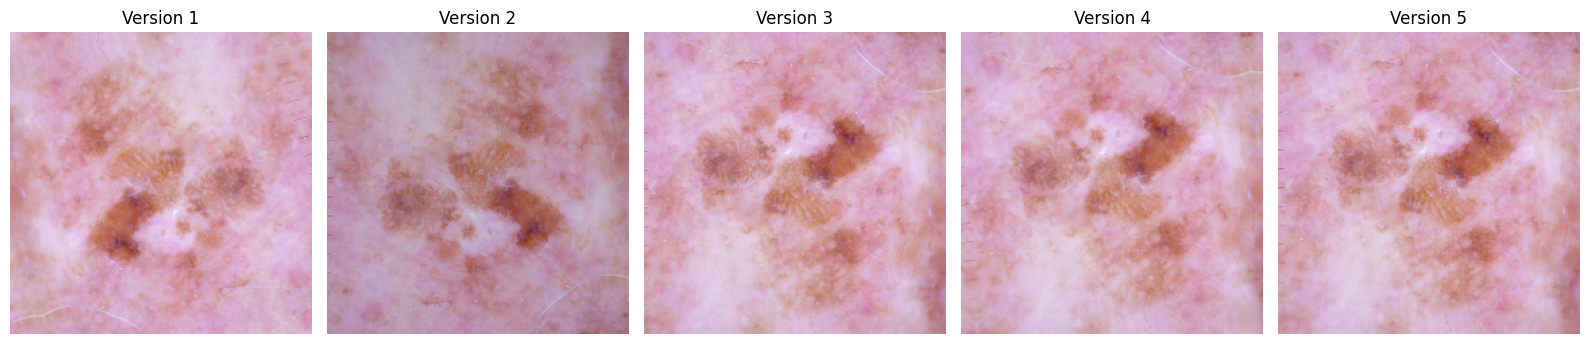

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Get an original training image
original_image, label = train_dataset[0]

# Reverse normalization for display
def display_image(tensor):
    image = tensor.permute(1, 2, 0).numpy()
    image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(image, 0, 1)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for i in range(5):
    # Retrieve the same image again
    # Random augmentation should change its appearance
    image, label = train_dataset[0]

    axes[i].imshow(display_image(image))
    axes[i].set_title(f"Version {i + 1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Retrieve the same validation image twice
image1, label1 = val_dataset[0]
image2, label2 = val_dataset[0]

assert torch.equal(image1, image2)
assert label1 == label2

print("Validation transforms are deterministic!")
print("Test 3 PASSED!")

Validation transforms are deterministic!
Test 3 PASSED!


In [13]:
# Find a sample image from your dataset
sample_id = train_df.iloc[0]["image_id"]

sample_path = None

for folder in IMG_DIRS:
    path = folder / f"{sample_id}.jpg"
    if path.exists():
        sample_path = path
        break

assert sample_path is not None

with Image.open(sample_path) as img:
    image = np.array(img.convert("RGB"))

accepted, reason, blur_score = check_image_quality(
    image, CONFIG
)

print("Accepted:", accepted)
print("Reason:", reason)
print("Blur score:", blur_score)

# Check that a tiny image is rejected
tiny_image = np.zeros((50, 50, 3), dtype=np.uint8)

accepted, reason, _ = check_image_quality(
    tiny_image, CONFIG
)

if CONFIG["quality_gate"]:
    assert not accepted
    print("Low-resolution image correctly rejected!")

print("Test 4 PASSED!")

Accepted: True
Reason: Accepted
Blur score: 62.19300515389575
Low-resolution image correctly rejected!
Test 4 PASSED!


In [14]:
# Check lesion leakage
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

assert train_lesions.isdisjoint(val_lesions)
assert train_lesions.isdisjoint(test_lesions)
assert val_lesions.isdisjoint(test_lesions)

# Every row must have a recognized diagnosis
for df in [train_df, val_df, test_df]:
    assert df["dx"].isin(LABEL_MAPPING).all()

print("No lesion leakage!")
print("All diagnosis labels recognized!")
print("Test 5 PASSED!")

No lesion leakage!
All diagnosis labels recognized!
Test 5 PASSED!


## Consistent Preprocessing During Inference

In [9]:
def prepare_inference_image(image_path, config):

    with Image.open(image_path) as img:
        image = np.array(img.convert("RGB"))

    # Check image quality BEFORE resizing
    accepted, reason, blur_score = check_image_quality(
        image, config
    )

    if not accepted:
        raise ValueError(f"Image rejected: {reason}")

    # Apply the same deterministic preprocessing
    image = preprocess_image(image, config)

    # Apply evaluation transforms (no randomness)
    transform = get_transforms(config, training=False)

    image_tensor = transform(image=image)["image"]

    # Add batch dimension
    return image_tensor.unsqueeze(0)
